# Customer Churn & Retention Analytics

## Objective
Analyze customer churn patterns, identify factors associated with customer attrition, and provide actionable recommendations to improve customer retention.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [2]:
df = pd.read_csv("../data/telco_customer_churn_clean.csv")

In [3]:
df.head()

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.columns

Index(['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents',
       'tenure', 'phone_service', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing',
       'payment_method', 'monthly_charges', 'total_charges', 'churn'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        7043 non-null   object 
 1   gender             7043 non-null   object 
 2   senior_citizen     7043 non-null   object 
 3   partner            7043 non-null   object 
 4   dependents         7043 non-null   object 
 5   tenure             7043 non-null   int64  
 6   phone_service      7043 non-null   object 
 7   multiple_lines     7043 non-null   object 
 8   internet_service   7043 non-null   object 
 9   online_security    7043 non-null   object 
 10  online_backup      7043 non-null   object 
 11  device_protection  7043 non-null   object 
 12  tech_support       7043 non-null   object 
 13  streaming_tv       7043 non-null   object 
 14  streaming_movies   7043 non-null   object 
 15  contract           7043 non-null   object 
 16  paperless_billing  7043 

In [7]:
df.describe()

,tenure,monthly_charges,total_charges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


In [8]:
df.describe(include='object')

,customer_id,gender,senior_citizen,partner,dependents,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,7590-VHVEG,Male,No,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,1,3555,5901,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


In [10]:
df.head()
# df.tail()

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Data Quality Assessment

### 1. Missing Values Analysis

In [11]:
df.isnull().sum()

customer_id           0
gender                0
senior_citizen        0
partner               0
dependents            0
tenure                0
phone_service         0
multiple_lines        0
internet_service      0
online_security       0
online_backup         0
device_protection     0
tech_support          0
streaming_tv          0
streaming_movies      0
contract              0
paperless_billing     0
payment_method        0
monthly_charges       0
total_charges        11
churn                 0
dtype: int64

In [14]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})
print(missing)
missing[missing['Missing Values'] > 0]

                   Missing Values  Missing Percentage
customer_id                     0            0.000000
gender                          0            0.000000
senior_citizen                  0            0.000000
partner                         0            0.000000
dependents                      0            0.000000
tenure                          0            0.000000
phone_service                   0            0.000000
multiple_lines                  0            0.000000
internet_service                0            0.000000
online_security                 0            0.000000
online_backup                   0            0.000000
device_protection               0            0.000000
tech_support                    0            0.000000
streaming_tv                    0            0.000000
streaming_movies                0            0.000000
contract                        0            0.000000
paperless_billing               0            0.000000
payment_method              

,Missing Values,Missing Percentage
total_charges,11,0.156183


In [15]:
df.duplicated().sum()

0

In [16]:
df['customer_id'].duplicated().sum()

0

In [17]:
df.nunique()

customer_id          7043
gender                  2
senior_citizen          2
partner                 2
dependents              2
tenure                 73
phone_service           2
multiple_lines          3
internet_service        3
online_security         3
online_backup           3
device_protection       3
tech_support            3
streaming_tv            3
streaming_movies        3
contract                3
paperless_billing       2
payment_method          4
monthly_charges      1585
total_charges        6530
churn                   2
dtype: int64

In [18]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].unique())


customer_id:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender:
['Female' 'Male']

senior_citizen:
['No' 'Yes']

partner:
['Yes' 'No']

dependents:
['No' 'Yes']

phone_service:
['No' 'Yes']

multiple_lines:
['No phone service' 'No' 'Yes']

internet_service:
['DSL' 'Fiber optic' 'No']

online_security:
['No' 'Yes' 'No internet service']

online_backup:
['Yes' 'No' 'No internet service']

device_protection:
['No' 'Yes' 'No internet service']

tech_support:
['No' 'Yes' 'No internet service']

streaming_tv:
['No' 'Yes' 'No internet service']

streaming_movies:
['No' 'Yes' 'No internet service']

contract:
['Month-to-month' 'One year' 'Two year']

paperless_billing:
['Yes' 'No']

payment_method:
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

churn:
['No' 'Yes']


In [19]:
df[df['total_charges'].isnull()]

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
488,4472-LVYGI,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,No,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,No,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,No,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,No,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,No,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,No,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [20]:
df[df['total_charges'].isnull()][['customer_id', 'tenure', 'monthly_charges', 'total_charges', 'churn']]

,customer_id,tenure,monthly_charges,total_charges,churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


### Handling Missing Values

In [21]:
# Check whether all missing TotalCharges records have zero tenure
df[df['total_charges'].isnull()]['tenure'].value_counts()

tenure
0    11
Name: count, dtype: int64

In [22]:
df['total_charges'] = df['total_charges'].fillna(0)

In [23]:
df['total_charges'].isnull().sum()

0

In [24]:
df.isnull().sum().sum()

0

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        7043 non-null   object 
 1   gender             7043 non-null   object 
 2   senior_citizen     7043 non-null   object 
 3   partner            7043 non-null   object 
 4   dependents         7043 non-null   object 
 5   tenure             7043 non-null   int64  
 6   phone_service      7043 non-null   object 
 7   multiple_lines     7043 non-null   object 
 8   internet_service   7043 non-null   object 
 9   online_security    7043 non-null   object 
 10  online_backup      7043 non-null   object 
 11  device_protection  7043 non-null   object 
 12  tech_support       7043 non-null   object 
 13  streaming_tv       7043 non-null   object 
 14  streaming_movies   7043 non-null   object 
 15  contract           7043 non-null   object 
 16  paperless_billing  7043 

### Missing Value Treatment

- Identified 11 missing values in TotalCharges.
- Investigated the affected customer records.
- All 11 customers had zero tenure.
- Replaced missing TotalCharges values with 0,
  based on the assumption that no charges had accumulated.
- Verified that no missing values remain.

## Univariate Analysis

### 1. Customer Churn Distribution

In [26]:
df['churn'].value_counts()

churn
No     5174
Yes    1869
Name: count, dtype: int64

In [27]:
df['churn'].value_counts(normalize=True) * 100

churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

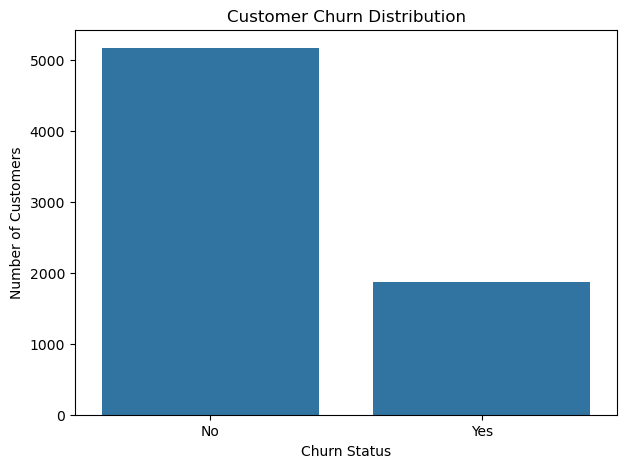

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

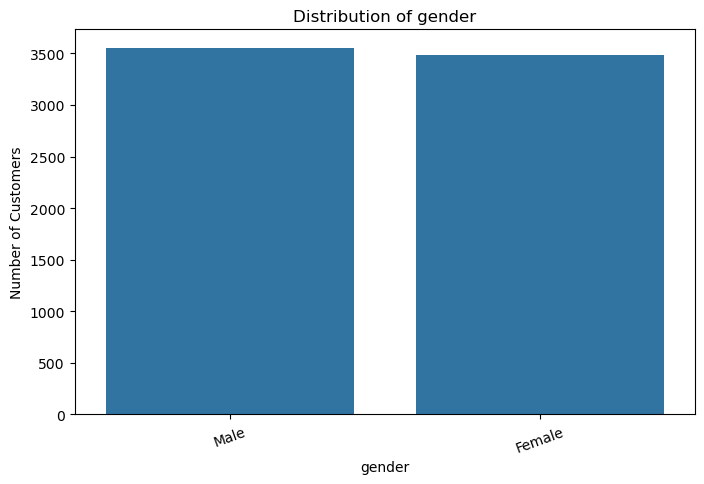

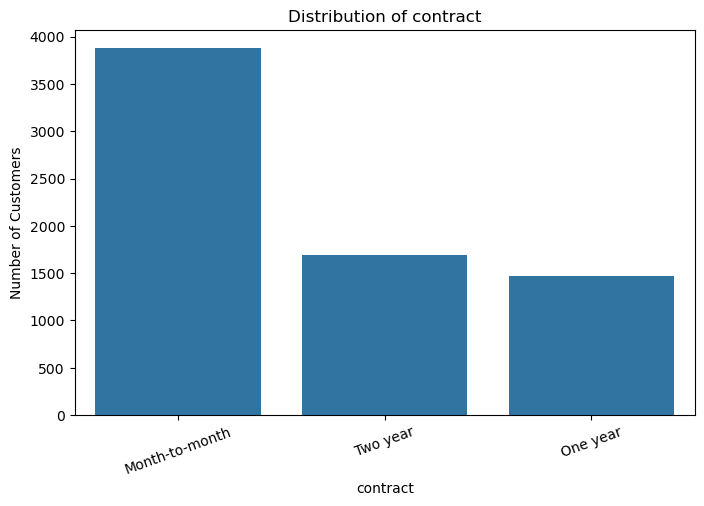

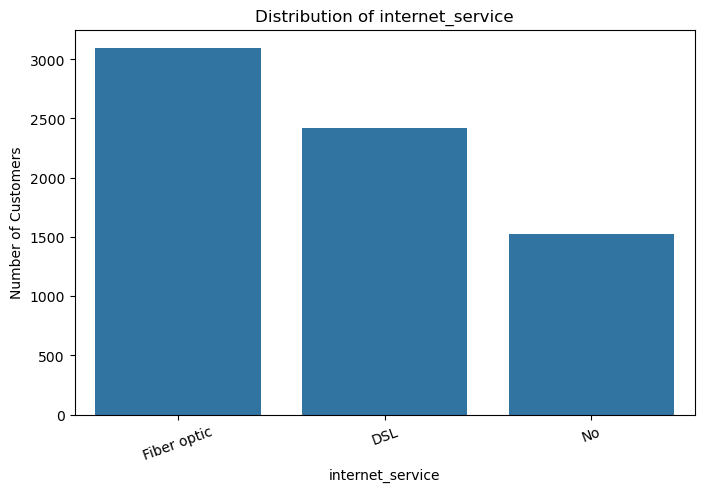

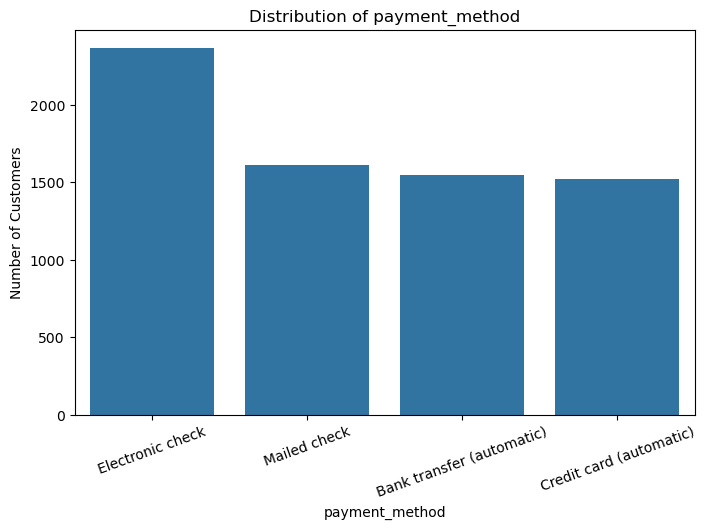

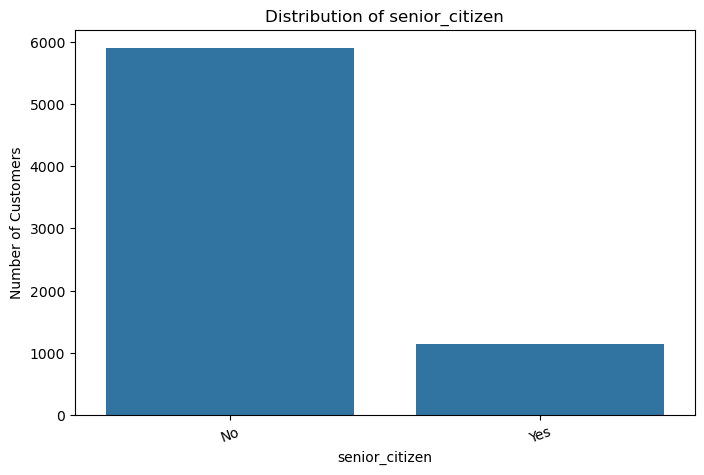

In [29]:
categorical_columns = [
    'gender',
    'contract',
    'internet_service',
    'payment_method',
    'senior_citizen'
]

for col in categorical_columns:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Number of Customers')
    plt.xticks(rotation=20)

    plt.show()

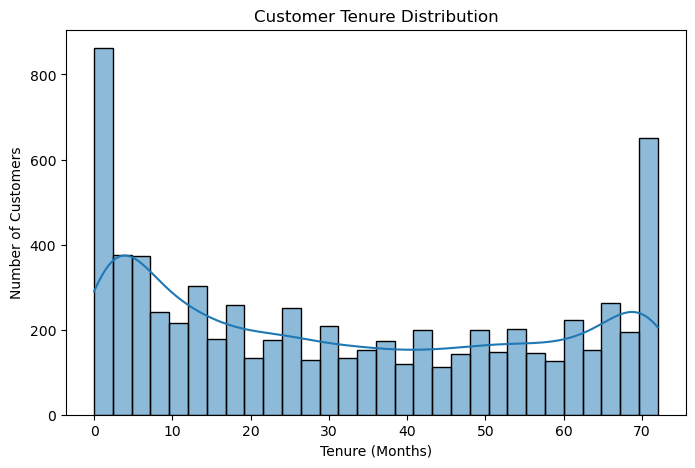

In [30]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='tenure', bins=30, kde=True)

plt.title('Customer Tenure Distribution')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

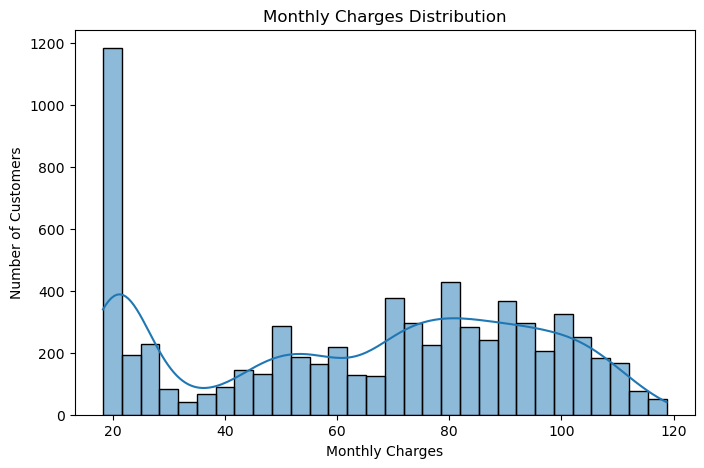

In [31]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='monthly_charges', bins=30, kde=True)

plt.title('Monthly Charges Distribution')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')

plt.show()

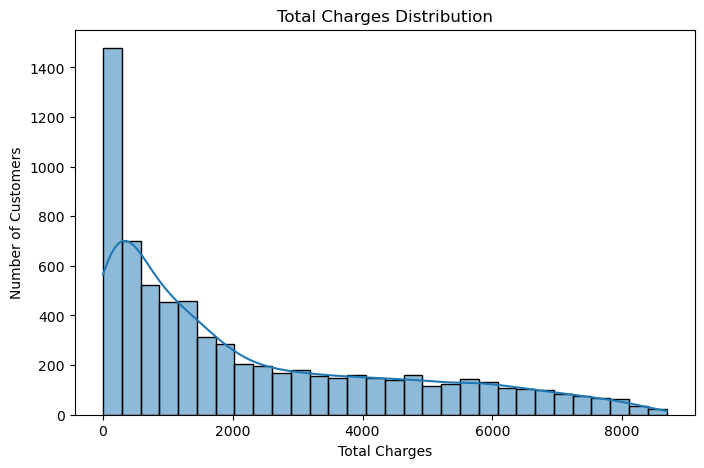

In [32]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='total_charges', bins=30, kde=True)

plt.title('Total Charges Distribution')
plt.xlabel('Total Charges')
plt.ylabel('Number of Customers')

plt.show()

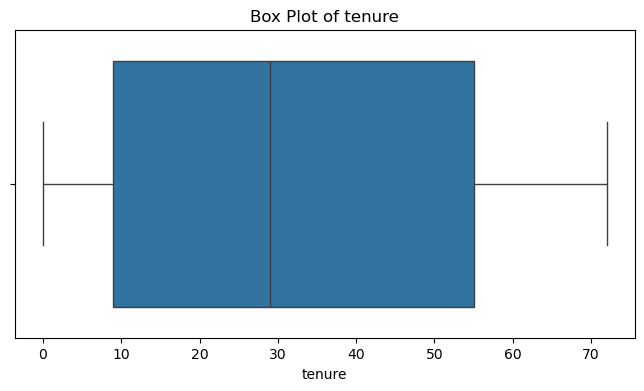

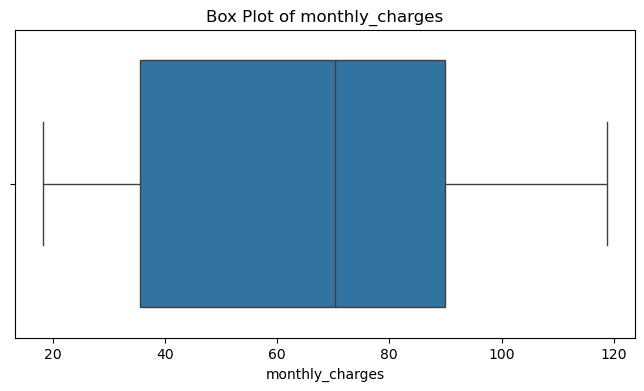

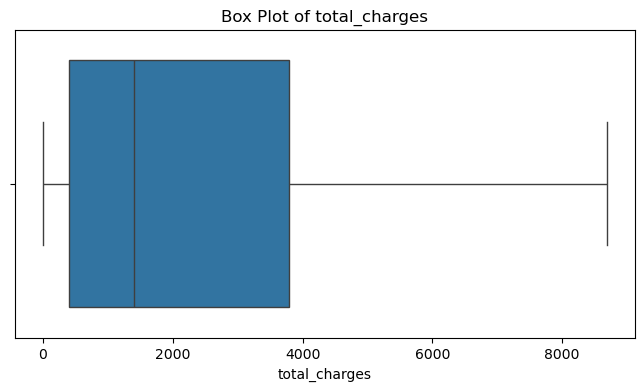

In [33]:
numerical_columns = [
    'tenure',
    'monthly_charges',
    'total_charges'
]

for col in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(data=df, x=col)

    plt.title(f'Box Plot of {col}')
    plt.show()

In [34]:
pd.crosstab(df['contract'], df['churn'])

churn,No,Yes
contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [35]:
contract_churn = pd.crosstab(
    df['contract'],
    df['churn'],
    normalize='index'
) * 100

contract_churn

churn,No,Yes
contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


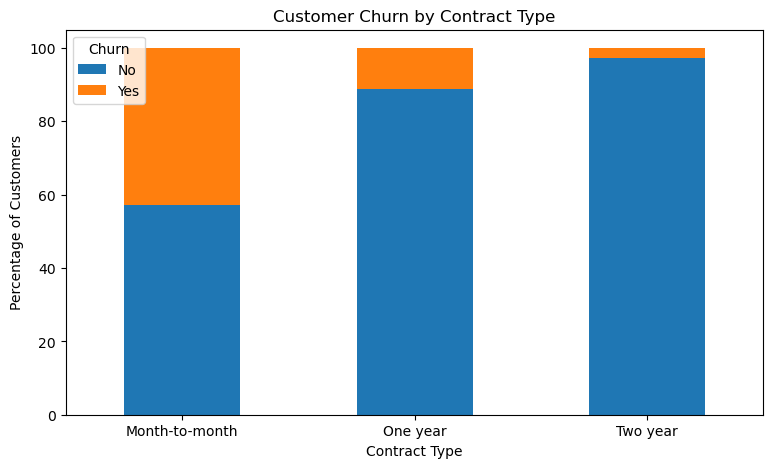

In [36]:
contract_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

In [37]:
payment_churn = pd.crosstab(
    df['payment_method'],
    df['churn'],
    normalize='index'
) * 100

payment_churn

churn,No,Yes
payment_method,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


In [38]:
payment_churn = pd.crosstab(
    df['payment_method'],
    df['churn'],
    normalize='index'
) * 100

payment_churn

churn,No,Yes
payment_method,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


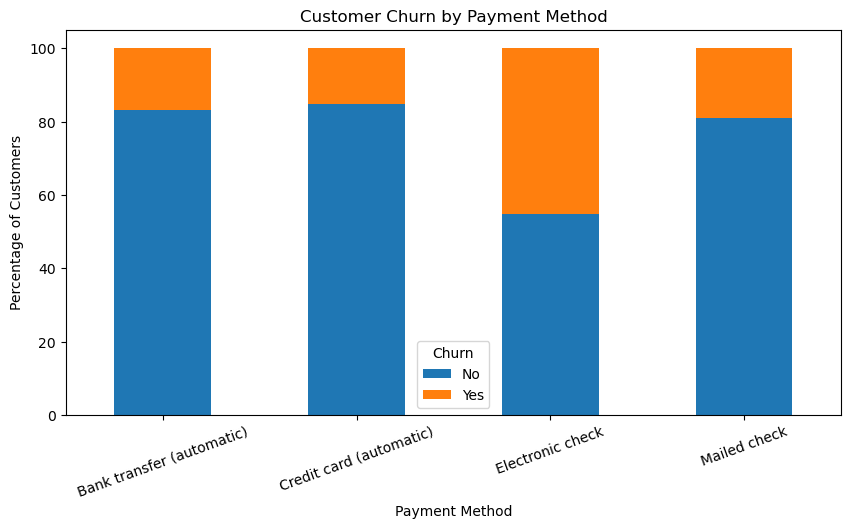

In [39]:
payment_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=20)
plt.legend(title='Churn')
plt.show()

In [40]:
internet_churn = pd.crosstab(
    df['internet_service'],
    df['churn'],
    normalize='index'
) * 100

internet_churn

churn,No,Yes
internet_service,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


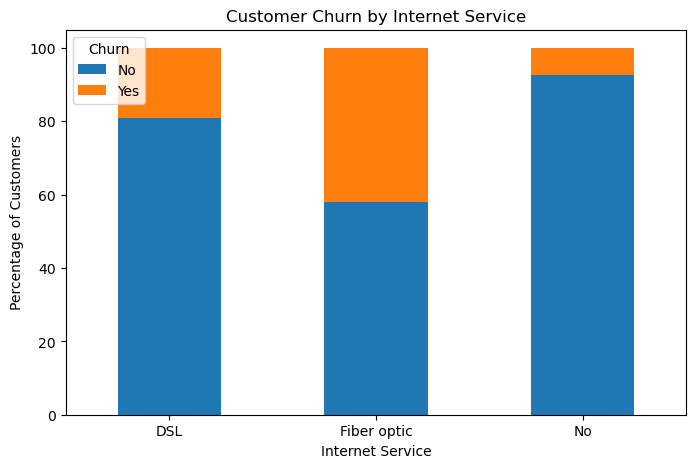

In [41]:
internet_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

In [42]:
support_churn = pd.crosstab(
    df['tech_support'],
    df['churn'],
    normalize='index'
) * 100

support_churn

churn,No,Yes
tech_support,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


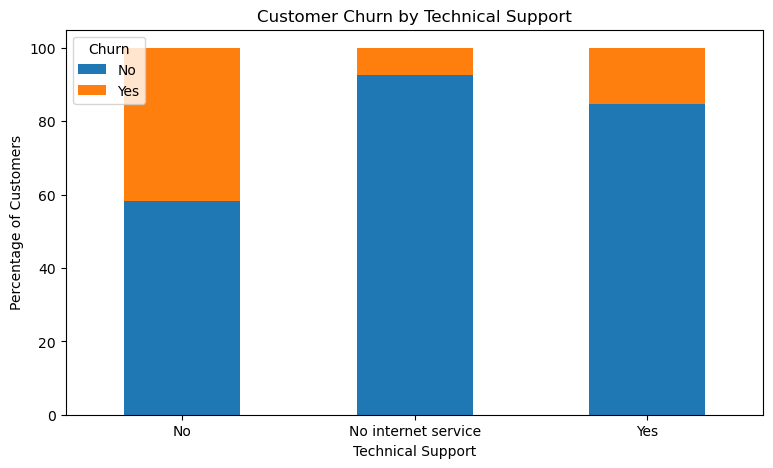

In [43]:
support_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Customer Churn by Technical Support')
plt.xlabel('Technical Support')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

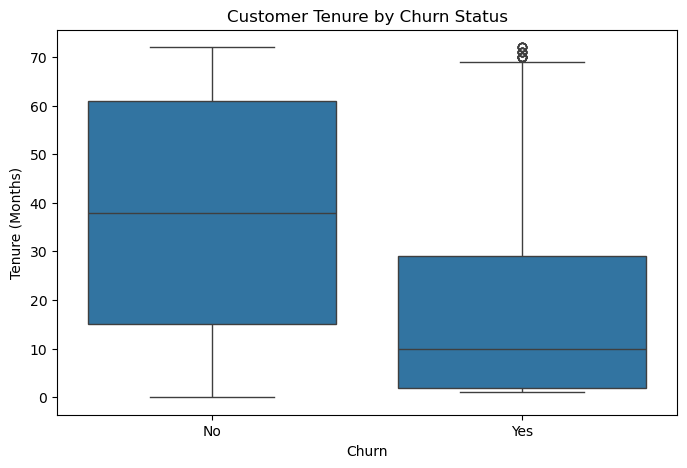

In [44]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='churn',
    y='tenure'
)

plt.title('Customer Tenure by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')

plt.show()

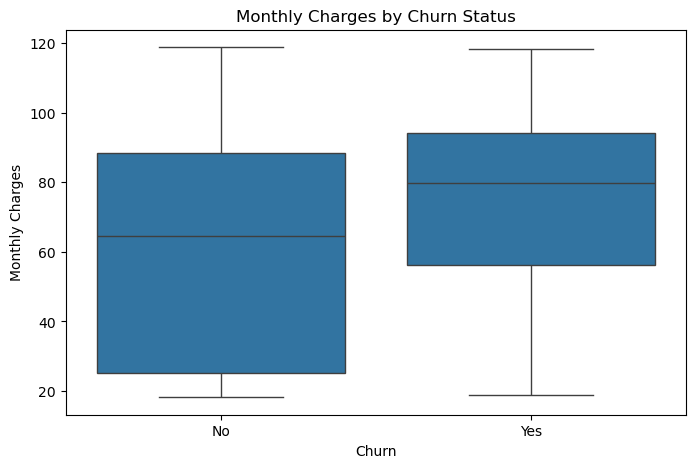

In [45]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='churn',
    y='monthly_charges'
)

plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()

In [46]:
df['tenure_group'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-12 Months', '13-24 Months',
            '25-48 Months', '49-72 Months']
)

In [47]:
contract_tenure = pd.pivot_table(
    df,
    index='contract',
    columns='tenure_group',
    values='churn',
    aggfunc=lambda x: (x == 'Yes').mean() * 100,
    observed=False
)

contract_tenure

tenure_group,0-12 Months,13-24 Months,25-48 Months,49-72 Months
contract,,,,
Month-to-month,51.354062,37.720488,32.917706,26.023392
One year,10.483871,8.121827,10.617761,12.933754
Two year,0.000000,0.000000,2.189781,3.325416


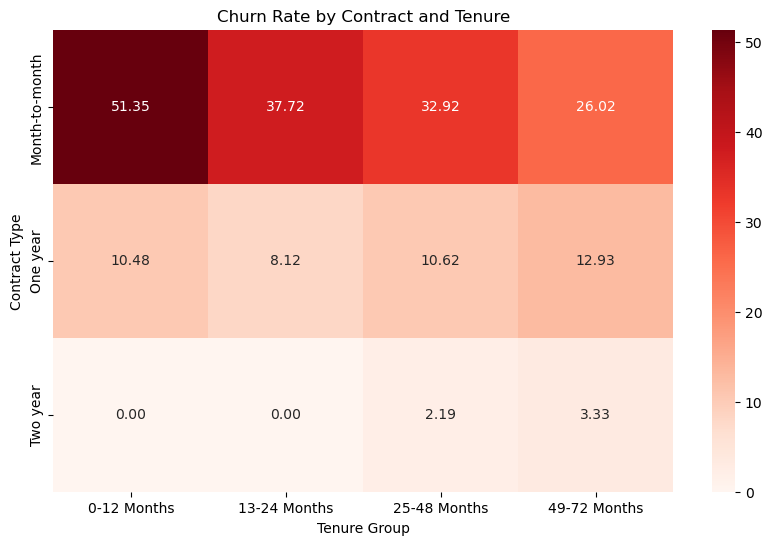

In [48]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    contract_tenure,
    annot=True,
    fmt='.2f',
    cmap='Reds'
)

plt.title('Churn Rate by Contract and Tenure')
plt.xlabel('Tenure Group')
plt.ylabel('Contract Type')

plt.show()

In [49]:
support_internet = pd.pivot_table(
    df,
    index='internet_service',
    columns='tech_support',
    values='churn',
    aggfunc=lambda x: (x == 'Yes').mean() * 100
)

support_internet

tech_support,No,No internet service,Yes
internet_service,,,
DSL,27.755430,NaN,9.677419
Fiber optic,49.372197,NaN,22.632794
No,NaN,7.40498,NaN


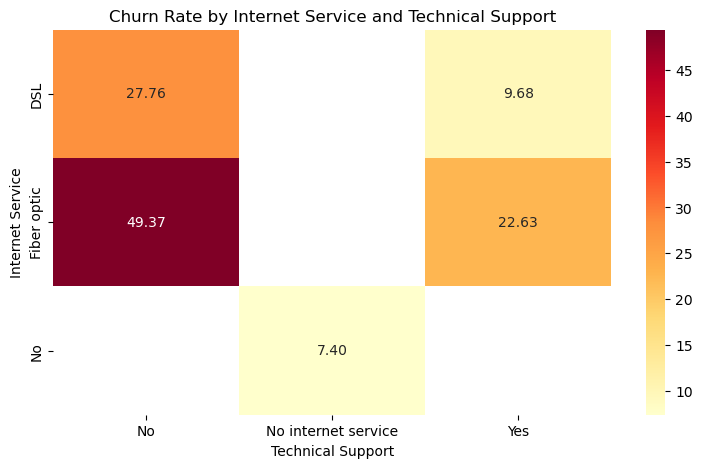

In [50]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    support_internet,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd'
)

plt.title('Churn Rate by Internet Service and Technical Support')
plt.xlabel('Technical Support')
plt.ylabel('Internet Service')

plt.show()

In [51]:
df['churn_numeric'] = df['churn'].map({
    'Yes': 1,
    'No': 0
})

In [52]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])

In [53]:
correlation = numeric_df.corr()

correlation

,tenure,monthly_charges,total_charges,churn_numeric
tenure,1.000000,0.247900,0.826178,-0.352229
monthly_charges,0.247900,1.000000,0.651174,0.193356
total_charges,0.826178,0.651174,1.000000,-0.198324
churn_numeric,-0.352229,0.193356,-0.198324,1.000000


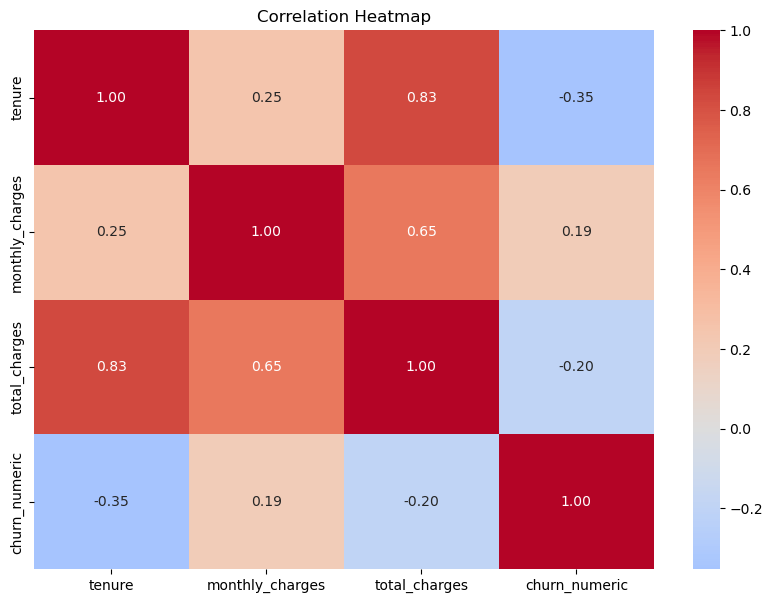

In [54]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Heatmap')

plt.show()

## Customer Segmentation

### 1. Segmentation Based on Customer Tenure

In [55]:
df['tenure_segment'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 48, 72],
    labels=['New', 'Established', 'Long-term']
)

In [56]:
df['tenure_segment'].value_counts()

tenure_segment
Established    2618
Long-term      2239
New            2186
Name: count, dtype: int64

In [57]:
tenure_analysis = df.groupby(
    'tenure_segment',
    observed=True
).agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', lambda x: (x == 'Yes').sum())
)

tenure_analysis['churn_rate'] = (
    tenure_analysis['churned_customers'] /
    tenure_analysis['total_customers'] * 100
)

tenure_analysis

,total_customers,churned_customers,churn_rate
tenure_segment,,,
New,2186,1037,47.438243
Established,2618,619,23.644003
Long-term,2239,213,9.513176


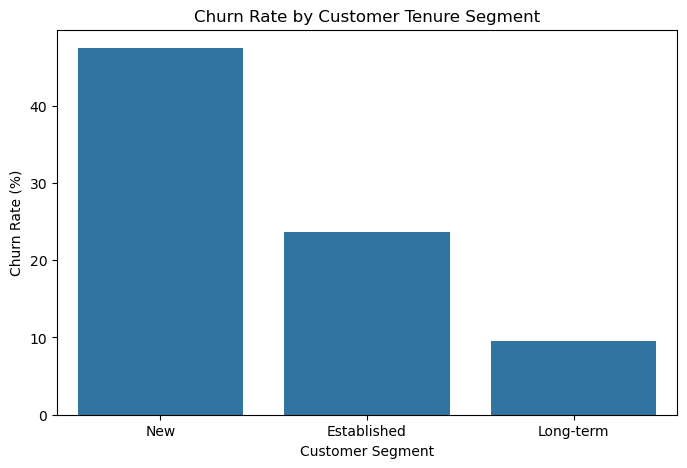

In [58]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=tenure_analysis.reset_index(),
    x='tenure_segment',
    y='churn_rate'
)

plt.title('Churn Rate by Customer Tenure Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Churn Rate (%)')

plt.show()

In [59]:
df['charge_segment'] = pd.cut(
    df['monthly_charges'],
    bins=[0, 50, 80, float('inf')],
    labels=['Low', 'Medium', 'High'],
    right=False
)

In [60]:
charge_analysis = df.groupby(
    'charge_segment',
    observed=True
).agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', lambda x: (x == 'Yes').sum())
)

charge_analysis['churn_rate'] = (
    charge_analysis['churned_customers'] /
    charge_analysis['total_customers'] * 100
)

charge_analysis

,total_customers,churned_customers,churn_rate
charge_segment,,,
Low,2294,361,15.736704
Medium,2072,598,28.861004
High,2677,910,33.993276


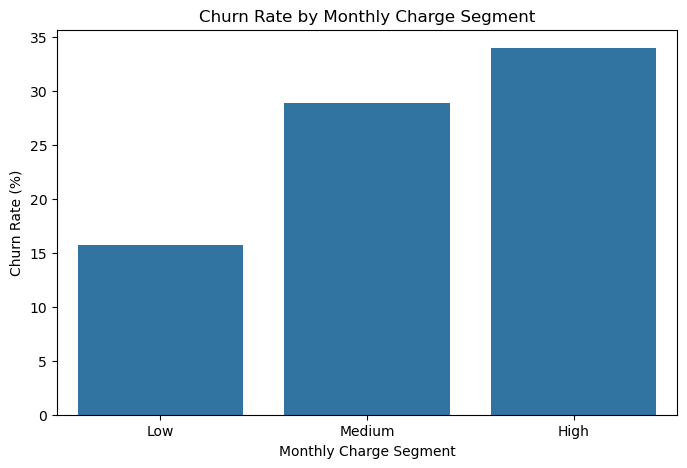

In [61]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=charge_analysis.reset_index(),
    x='charge_segment',
    y='churn_rate'
)

plt.title('Churn Rate by Monthly Charge Segment')
plt.xlabel('Monthly Charge Segment')
plt.ylabel('Churn Rate (%)')

plt.show()

In [62]:
segment_analysis = pd.pivot_table(
    df,
    index='tenure_segment',
    columns='charge_segment',
    values='churn',
    aggfunc=lambda x: (x == 'Yes').mean() * 100,
    observed=False
)

segment_analysis

charge_segment,Low,Medium,High
tenure_segment,,,
New,30.810811,51.913265,72.327044
Established,7.506053,20.711563,39.203980
Long-term,2.578269,5.588822,14.309623


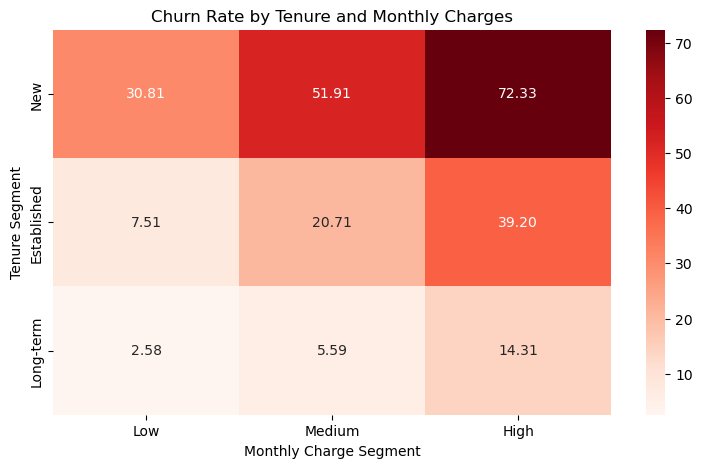

In [63]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    segment_analysis,
    annot=True,
    fmt='.2f',
    cmap='Reds'
)

plt.title('Churn Rate by Tenure and Monthly Charges')
plt.xlabel('Monthly Charge Segment')
plt.ylabel('Tenure Segment')

plt.show()

In [64]:
high_risk_customers = df[
    (df['tenure'] <= 12) &
    (df['monthly_charges'] >= 80) &
    (df['churn'] == 'Yes')
]

high_risk_customers[
    ['customer_id', 'tenure', 'monthly_charges',
     'contract', 'payment_method', 'churn']
].head(10)

,customer_id,tenure,monthly_charges,contract,payment_method,churn
5,9305-CDSKC,8,99.65,Month-to-month,Electronic check,Yes
39,8168-UQWWF,11,97.85,Month-to-month,Bank transfer (automatic),Yes
47,7760-OYPDY,2,80.65,Month-to-month,Electronic check,Yes
53,7495-OOKFY,8,80.65,Month-to-month,Credit card (automatic),Yes
64,5698-BQJOH,9,94.40,Month-to-month,Electronic check,Yes
117,5299-RULOA,10,100.25,Month-to-month,Electronic check,Yes
151,3874-EQOEP,7,95.00,Month-to-month,Mailed check,Yes
171,1875-QIVME,2,104.40,Month-to-month,Electronic check,Yes
182,9367-WXLCH,8,84.50,Month-to-month,Bank transfer (automatic),Yes
191,2472-OVKUP,6,91.00,Month-to-month,Electronic check,Yes


# Business Insights & Recommendations

In [65]:
total_customers = df['customer_id'].nunique()

churned_customers = (df['churn'] == 'Yes').sum()

retained_customers = (df['churn'] == 'No').sum()

churn_rate = churned_customers / total_customers * 100

retention_rate = retained_customers / total_customers * 100

monthly_revenue = df['monthly_charges'].sum()

churned_revenue_exposure = df.loc[
    df['churn'] == 'Yes', 'monthly_charges'
].sum()

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print("Churn Rate:", round(churn_rate, 2), "%")
print("Retention Rate:", round(retention_rate, 2), "%")
print("Total Monthly Charges:", round(monthly_revenue, 2))
print("Churned Monthly Charge Exposure:", round(churned_revenue_exposure, 2))

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54 %
Retention Rate: 73.46 %
Total Monthly Charges: 456116.6
Churned Monthly Charge Exposure: 139130.85


In [66]:
def calculate_churn_rate(column):

    result = df.groupby(column).agg(
        total_customers=('customer_id', 'count'),
        churned_customers=('churn', lambda x: (x == 'Yes').sum())
    )

    result['churn_rate'] = (
        result['churned_customers'] /
        result['total_customers'] * 100
    )

    return result.sort_values('churn_rate', ascending=False)

In [67]:
contract_insights = calculate_churn_rate('contract')
payment_insights = calculate_churn_rate('payment_method')
internet_insights = calculate_churn_rate('internet_service')
support_insights = calculate_churn_rate('tech_support')

display(contract_insights)
display(payment_insights)
display(internet_insights)
display(support_insights)

,total_customers,churned_customers,churn_rate
contract,,,
Month-to-month,3875,1655,42.709677
One year,1473,166,11.269518
Two year,1695,48,2.831858


,total_customers,churned_customers,churn_rate
payment_method,,,
Electronic check,2365,1071,45.285412
Mailed check,1612,308,19.106700
Bank transfer (automatic),1544,258,16.709845
Credit card (automatic),1522,232,15.243101


,total_customers,churned_customers,churn_rate
internet_service,,,
Fiber optic,3096,1297,41.892765
DSL,2421,459,18.959108
No,1526,113,7.404980


,total_customers,churned_customers,churn_rate
tech_support,,,
No,3473,1446,41.635474
Yes,2044,310,15.166341
No internet service,1526,113,7.404980


In [68]:
df.to_csv(
    '../data/telco_customer_churn_final.csv',
    index=False
)

In [69]:
df['tenure_segment'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 48, 72],
    labels=['New', 'Established', 'Long-term']
)

In [70]:
tenure_analysis = df.groupby('tenure_segment', observed=False).agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', lambda x: (x == 'Yes').sum())
)

tenure_analysis['churn_rate'] = (
    tenure_analysis['churned_customers'] /
    tenure_analysis['total_customers']
) * 100

tenure_analysis

,total_customers,churned_customers,churn_rate
tenure_segment,,,
New,2186,1037,47.438243
Established,2618,619,23.644003
Long-term,2239,213,9.513176


In [71]:
df['charge_segment'] = pd.cut(
    df['monthly_charges'],
    bins=[0, 50, 80, float('inf')],
    labels=['Low', 'Medium', 'High'],
    right=False
)

In [72]:
charge_analysis = df.groupby('charge_segment', observed=False).agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', lambda x: (x == 'Yes').sum())
)

charge_analysis['churn_rate'] = (
    charge_analysis['churned_customers'] /
    charge_analysis['total_customers']
) * 100

charge_analysis

,total_customers,churned_customers,churn_rate
charge_segment,,,
Low,2294,361,15.736704
Medium,2072,598,28.861004
High,2677,910,33.993276


In [73]:
segment_analysis = pd.pivot_table(
    df,
    index='tenure_segment',
    columns='charge_segment',
    values='churn',
    aggfunc=lambda x: (x == 'Yes').mean() * 100,
    observed=False
)

segment_analysis

charge_segment,Low,Medium,High
tenure_segment,,,
New,30.810811,51.913265,72.327044
Established,7.506053,20.711563,39.203980
Long-term,2.578269,5.588822,14.309623


In [76]:
df.to_csv('../data/telco_customer_churn_final.csv', index=False)